# Тестовое задание

### Требования к оформлению

- Язык: **Python 3**
- Код организован в функции с понятными названиями и сигнатурами.
- Графики подписаны (заголовок, оси).
- Текстовые пояснения между блоками кода: что делаете, что наблюдаете.

### Формат сдачи

Jupyter-ноутбук (`.ipynb`) с выполненным кодом и результатами. Ноутбук должен быть запускаемым «из коробки» (все ячейки выполняются последовательно без ошибок).


### Среда

Первый запуск устанавливает зависимости и скачивает Speech Commands v2 (~2.3 ГБ). Все результаты сохраняются внутри блокнота; последняя ячейка дополнительно создаёт требуемый `kws.onnx`.

In [1]:
%pip install -q torch==2.8.0 torchaudio==2.8.0 numpy matplotlib soundfile scikit-learn onnx onnxruntime

You should consider upgrading via the '/Users/almazgajnetdinov/Developer/VK2/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


### Часть 1. STFT (Short-Time Fourier Transform)


1. **Реализуйте функцию STFT** — на вход подаётся одномерный массив аудиосигнала (numpy-array), на выходе — комплексная спектрограмма.
   - Разрешается использовать `np.fft.rfft` для вычисления FFT отдельного фрейма.
   - Не используйте готовые реализации STFT (`librosa.stft`, `torch.stft`, `scipy.signal.stft` и т.п.).
   - Параметры функции: `n_fft` (размер окна FFT), `hop_length` (шаг между фреймами), `window_fn` (оконная функция).

STFT реализую разбиением на фреймы, умножением на окно и `np.fft.rfft`. Комплексный результат имеет форму `(n_fft // 2 + 1, число фреймов)`. Начало сигнала не дополняется, последний фрейм справа дополняется нулями.

In [2]:
from pathlib import Path
from typing import Callable
import math
import random
import copy
import tarfile
import urllib.request
import numpy as np
import soundfile as sf
import torch
import torchaudio
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from IPython.display import Audio, display

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(4)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA = Path('data')
DATA.mkdir(exist_ok=True)

def stft(signal: np.ndarray, n_fft: int, hop_length: int,
         window_fn: Callable[[int], np.ndarray]) -> np.ndarray:
    signal = np.asarray(signal, dtype=np.float64)
    if signal.ndim != 1 or signal.size == 0:
        raise ValueError('Нужен непустой одномерный аудиосигнал.')
    if n_fft < 1 or hop_length < 1:
        raise ValueError('n_fft и hop_length должны быть положительными.')
    window = np.asarray(window_fn(n_fft))
    if window.shape != (n_fft,):
        raise ValueError('Окно должно иметь длину n_fft.')

    n_frames = 1 + math.ceil(max(0, len(signal)-n_fft) / hop_length)
    padded_length = (n_frames-1)*hop_length + n_fft
    padded = np.pad(signal, (0, padded_length-len(signal)))
    frames = [padded[i*hop_length:i*hop_length+n_fft] * window for i in range(n_frames)]
    return np.fft.rfft(np.stack(frames), axis=-1).T

2. **Реализуйте оконные функции:**
   - Прямоугольное окно (rectangular)
   - Окно Ханна (Hann)
   - Окно Хэмминга (Hamming)


Использую симметричные окна с делителем `n−1`; для длины 1 окно равно единице. Сравниваю формулы с NumPy и проверяю STFT на синусоиде.

In [3]:
def rectangular(n: int) -> np.ndarray:
    return np.ones(n)


def hann(n: int) -> np.ndarray:
    if n == 1:
        return np.ones(1)
    return 0.5 - 0.5 * np.cos(2 * np.pi * np.arange(n) / (n-1))


def hamming(n: int) -> np.ndarray:
    if n == 1:
        return np.ones(1)
    return 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(n) / (n-1))

assert np.allclose(hann(16), np.hanning(16))
assert np.allclose(hamming(16), np.hamming(16))
assert stft(np.ones(2), 4, 2, rectangular).shape == (3, 1)

tone = np.sin(2*np.pi*8*np.arange(256)/256)
assert np.argmax(abs(stft(tone, 256, 128, rectangular))[:, 0]) == 8
print('Окна и STFT: PASS')

Окна и STFT: PASS


3. **Визуализация:**
   - Загрузите любой аудиофайл (можно использовать `librosa.example('trumpet')` или свой файл).
   - Постройте спектрограмму (модуль STFT в дБ) для каждой из трёх оконных функций.
   - На отдельном графике покажите, как меняется спектрограмма при изменении `n_fft` (например, 256, 512, 1024, 2048) при фиксированном `hop_length`.
   - Кратко опишите наблюдения: что меняется и почему.




Для сравнения использую одну речевую запись и общую шкалу дБ. Делю модуль спектра на сумму окна, чтобы различия усиления окон не определяли картину.

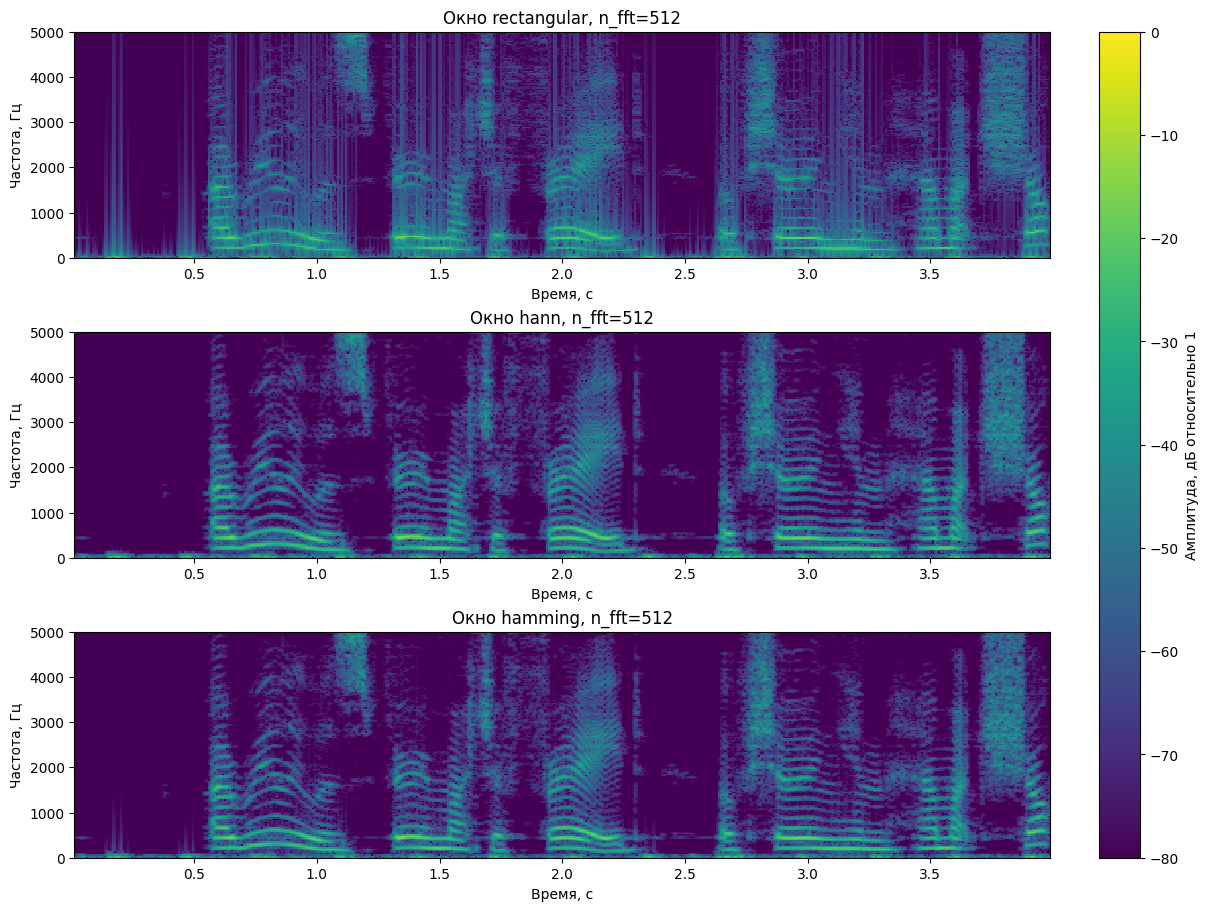

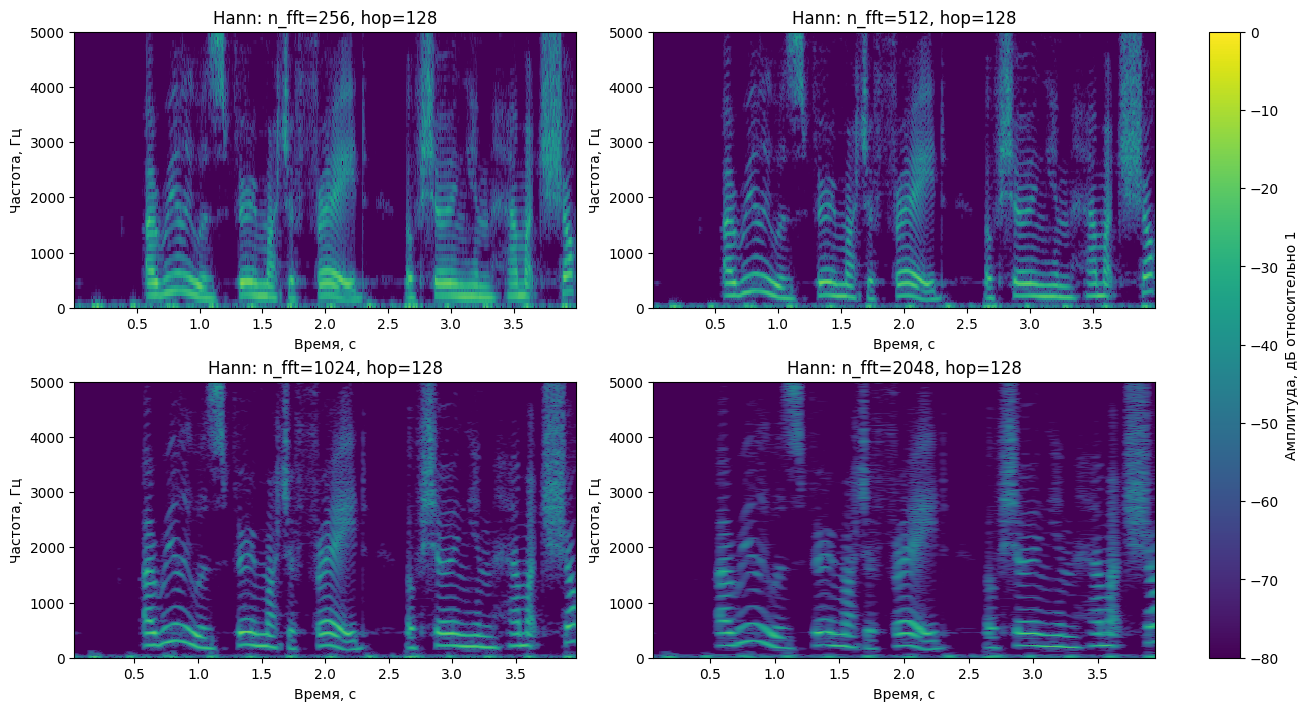

In [4]:
def load_audio(path: Path, sample_rate: int = 16000) -> np.ndarray:
    audio, sr = sf.read(path, dtype='float32', always_2d=True)
    signal = torch.from_numpy(audio.mean(axis=1))
    if sr != sample_rate:
        signal = torchaudio.functional.resample(signal, sr, sample_rate)
    return signal.numpy()


def plot_spectrogram(signal, sr, n_fft, hop_length, window_fn, ax, title):
    spectrum = stft(signal, n_fft, hop_length, window_fn)

    magnitude = np.abs(spectrum) / max(window_fn(n_fft).sum(), 1e-12)
    db = 20 * np.log10(np.maximum(magnitude, 1e-8))
    times = (np.arange(spectrum.shape[1])*hop_length + n_fft/2) / sr
    frequencies = np.fft.rfftfreq(n_fft, 1/sr)
    image = ax.pcolormesh(times, frequencies, db, shading='auto', vmin=-80, vmax=0)
    ax.set(title=title, xlabel='Время, с', ylabel='Частота, Гц', ylim=(0, 5000))
    return image


speech_path = DATA / '1688-142285-0007.wav'
if not speech_path.exists():
    urllib.request.urlretrieve(
        'https://download.pytorch.org/torchaudio/tutorial-assets/ctc-decoding/1688-142285-0007.wav',
        speech_path,
    )
sr = 16000
signal = load_audio(speech_path, sr)[:sr*4]
display(Audio(signal, rate=sr))
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
for ax, window_fn in zip(axes, [rectangular, hann, hamming]):
    im = plot_spectrogram(signal, sr, 512, 128, window_fn, ax, f'Окно {window_fn.__name__}, n_fft=512')
fig.colorbar(im, ax=axes, label='Амплитуда, дБ относительно 1')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
for ax, n_fft in zip(axes.flat, [256, 512, 1024, 2048]):
    im = plot_spectrogram(signal, sr, n_fft, 128, hann, ax, f'Hann: n_fft={n_fft}, hop=128')
fig.colorbar(im, ax=axes, label='Амплитуда, дБ относительно 1')
plt.show()

**Наблюдения.** Прямоугольное окно даёт более заметное растекание энергии около гармоник и резких границ. Hann и Hamming подавляют боковые лепестки, но расширяют главный лепесток. При увеличении `n_fft` гармоники различаются лучше по частоте, а краткие изменения сильнее размазываются по времени: окно охватывает более длинный участок. При фиксированном `hop_length=128` шаг сетки по времени остаётся 8 мс; это не означает неизменную временную разрешающую способность.

4. **Реализуйте преобразования** между шкалами частот:
   - Hz → Mel: $m = 2595 \cdot \log_{10}(1 + f / 700)$
   - Mel → Hz: $f = 700 \cdot (10^{m/2595} - 1)$

Преобразования применяются как к скаляру, так и к массиву. Проверяю, что обратное преобразование восстанавливает исходные частоты.

In [5]:
def hz_to_mel(frequency):
    frequency = np.asarray(frequency, dtype=float)
    if np.any(frequency < 0):
        raise ValueError('Частота не может быть отрицательной.')
    return 2595 * np.log10(1 + frequency / 700)


def mel_to_hz(mel):
    mel = np.asarray(mel, dtype=float)
    if np.any(mel < 0):
        raise ValueError('Значение Mel не может быть отрицательным.')
    return 700 * (10 ** (mel / 2595) - 1)

frequencies = np.array([0, 100, 1000, 4000, 8000])
assert np.allclose(mel_to_hz(hz_to_mel(frequencies)), frequencies)
print('Гц: ', frequencies)
print('Mel:', np.round(hz_to_mel(frequencies), 2))

Гц:  [   0  100 1000 4000 8000]
Mel: [   0.    150.49  999.99 2146.06 2840.02]


### Часть 2. KWS (Key Word Spotting)

*Google Speech Commands* — это набор односекундных аудиофайлов в формате .wav, предназначенный для обучения систем распознавания коротких голосовых команд (Keyword Spotting).

**Количество слов**: 35 различных английских слов.

**Основные классы**: yes, no, up, down, left, right, on, off, stop, go, а также цифры от zero до nine и другие.

**Основные характеристики (v2)**:

**Объем**: 105 829 аудиозаписей.

**Формат**: Одноканальные WAV-файлы, 16 кГц, 16 бит, длительностью до 1 секунды.

In [6]:
CLASSES = ['yes', 'no', 'on', 'off']
SAMPLE_RATE = 16000
print('Устройство:', DEVICE)

Устройство: cpu


Архив содержит все слова; извлекаю только четыре нужных класса и список тестовых записей. Повторный запуск использует уже подготовленные файлы.

In [7]:
def prepare_speech_commands(data_root: Path) -> Path:
    folder = data_root / 'speech_commands'
    marker = folder / '.four_classes_ready'
    if marker.exists():
        return folder
    archive = data_root / 'speech_commands.tar.gz'
    if not archive.exists():
        print('Скачивание Speech Commands v2 (~2.3 ГБ)...')
        urllib.request.urlretrieve(
            'https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz',
            archive,
        )
    folder.mkdir(exist_ok=True)

    with tarfile.open(archive, 'r:gz') as tar:
        for member in tar:
            relative = Path(member.name)
            if relative.is_absolute() or '..' in relative.parts or not member.isfile():
                continue
            wanted = (len(relative.parts) == 2 and relative.parts[0] in CLASSES
                      and relative.suffix == '.wav') or relative.name == 'testing_list.txt'
            if wanted:
                destination = folder / relative
                destination.parent.mkdir(parents=True, exist_ok=True)
                source = tar.extractfile(member)
                with source, destination.open('wb') as output:
                    output.write(source.read())
    marker.touch()
    return folder

speech_commands = prepare_speech_commands(DATA)
print({word: len(list((speech_commands/word).glob('*.wav'))) for word in CLASSES})

Скачивание Speech Commands v2 (~2.3 ГБ)...
{'yes': 4044, 'no': 3941, 'on': 3845, 'off': 3745}


#### Задание


Необходимо обучить модель классификации с четырьмя классами: **yes, no, on, off**.

Датасет необходимо самостоятельно подготовить и разделить на обучающую и валидационную части в соотношении 75% / 25%.

Во время обучения требуется отслеживать лосс и метрику качества на train- и valid-выборках, а затем построить графики их изменений по эпохам.


*Можете использовать любые подходы, модели и т.д.*

Сначала откладываю официальную тестовую часть и не использую её для выбора модели. Остальные файлы делю стратифицированно на train/valid в соотношении 75/25 с округлением до целых файлов. Это разбиение по записям: дикторы train и valid могут пересекаться. Официальный test отделён по дикторам от остальных частей корпуса. Каждый WAV привожу к 16 кГц и одной секунде; log-mel считаю один раз и храню в памяти.

In [8]:
def split_files(folder: Path):
    test_names = set((folder/'testing_list.txt').read_text().splitlines())
    remaining, test = [], []
    for label, word in enumerate(CLASSES):
        for path in sorted((folder/word).glob('*.wav')):
            pair = (path, label)
            (test if path.relative_to(folder).as_posix() in test_names else remaining).append(pair)
    train, valid = train_test_split(remaining, test_size=0.25, random_state=0,
                                    stratify=[label for _, label in remaining])
    return train, valid, test

train_files, valid_files, test_files = split_files(speech_commands)
assert not ({p for p,_ in train_files} & {p for p,_ in valid_files})
assert not ({p for p,_ in train_files+valid_files} & {p for p,_ in test_files})
print(f'Train: {len(train_files)}, valid: {len(valid_files)}, test: {len(test_files)}')
print(f'Доля train среди train+valid: {len(train_files)/(len(train_files)+len(valid_files)):.3%}')

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE, n_fft=512, win_length=400,
    hop_length=160, n_mels=40,
)

def audio_to_features(waveforms: torch.Tensor) -> torch.Tensor:
    features = torch.log(mel_transform(waveforms) + 1e-6)
    mean = features.mean(dim=(-2,-1), keepdim=True)
    std = features.std(dim=(-2,-1), keepdim=True).clamp_min(1e-5)
    return ((features-mean)/std).unsqueeze(1)


def make_dataset(files: list) -> TensorDataset:
    features, targets = [], []
    for start in range(0, len(files), 128):
        batch = files[start:start+128]
        waveforms = []
        for path, label in batch:
            audio = load_audio(path, SAMPLE_RATE)
            audio = np.pad(audio[:SAMPLE_RATE], (0, max(0, SAMPLE_RATE-len(audio))))
            waveforms.append(audio)
            targets.append(label)
        features.append(audio_to_features(torch.from_numpy(np.stack(waveforms))))
    return TensorDataset(torch.cat(features), torch.tensor(targets))

train_data = make_dataset(train_files)
valid_data = make_dataset(valid_files)
test_data = make_dataset(test_files)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
valid_loader = DataLoader(valid_data, batch_size=128)
test_loader = DataLoader(test_data, batch_size=128)
print('Признаки:', tuple(train_data.tensors[0].shape))

Train: 10464, valid: 3489, test: 1622
Доля train среди train+valid: 74.995%
Признаки: (10464, 1, 40, 101)


Небольшая CNN получает нормализованный log-mel и выдаёт четыре логита. Архитектура без предобучения; softmax нужен только при предсказании, а cross-entropy принимает логиты.

In [9]:
class KeywordCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.AvgPool2d((2, 5)), nn.Flatten(),
            nn.Linear(64*5*5, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 4),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.network(features)

model = KeywordCNN().to(DEVICE)
print('Число параметров:', sum(p.numel() for p in model.parameters()))

Число параметров: 126020


Обучаю 12 эпох Adam. После каждой эпохи считаю loss и accuracy на train и valid; сохраняю веса с минимальным validation loss. Тестовая выборка в этом выборе не участвует.

In [10]:
def run_epoch(model: nn.Module, loader: DataLoader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total = 0., 0, 0
    with torch.set_grad_enabled(training):
        for features, targets in loader:
            features, targets = features.to(DEVICE), targets.to(DEVICE)
            logits = model(features)
            loss = nn.functional.cross_entropy(logits, targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(targets)
            total_correct += (logits.argmax(1) == targets).sum().item()
            total += len(targets)
    return total_loss/total, total_correct/total

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = {'train_loss': [], 'valid_loss': [], 'train_acc': [], 'valid_acc': []}
best_loss, best_state = float('inf'), None
for epoch in range(1, 13):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer)
    valid_loss, valid_acc = run_epoch(model, valid_loader)
    for key, value in zip(history, [train_loss, valid_loss, train_acc, valid_acc]):
        history[key].append(value)
    if valid_loss < best_loss:
        best_loss, best_state = valid_loss, copy.deepcopy(model.state_dict())
    print(f'{epoch:2d}: train loss={train_loss:.4f}, acc={train_acc:.3f}; '
          f'valid loss={valid_loss:.4f}, acc={valid_acc:.3f}')
model.load_state_dict(best_state)
model.eval()

 1: train loss=0.7302, acc=0.688; valid loss=0.3381, acc=0.885
 2: train loss=0.2998, acc=0.891; valid loss=0.2108, acc=0.927
 3: train loss=0.2093, acc=0.919; valid loss=0.1896, acc=0.933
 4: train loss=0.1637, acc=0.938; valid loss=0.1469, acc=0.947
 5: train loss=0.1461, acc=0.945; valid loss=0.1317, acc=0.947
 6: train loss=0.1257, acc=0.953; valid loss=0.1381, acc=0.948
 7: train loss=0.1137, acc=0.958; valid loss=0.1301, acc=0.950
 8: train loss=0.1049, acc=0.958; valid loss=0.1189, acc=0.954
 9: train loss=0.0902, acc=0.966; valid loss=0.1169, acc=0.959
10: train loss=0.0844, acc=0.968; valid loss=0.1142, acc=0.957
11: train loss=0.0766, acc=0.968; valid loss=0.1065, acc=0.962
12: train loss=0.0720, acc=0.972; valid loss=0.1139, acc=0.959


KeywordCNN(
  (network): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AvgPool2d(kernel_size=(2, 5), stride=(2, 5), padding=0)
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=1600, out_features=64, bias=True)
    (11): ReLU()
    (12): Dropout(p=0.2, inplace=False)
    (13): Linear(in_features=64, out_features=4, bias=True)
  )
)

Падение train loss показывает обучение. Разрыв train/valid помогает заметить переобучение; окончательные веса выбираются по valid loss, а не по последней эпохе.

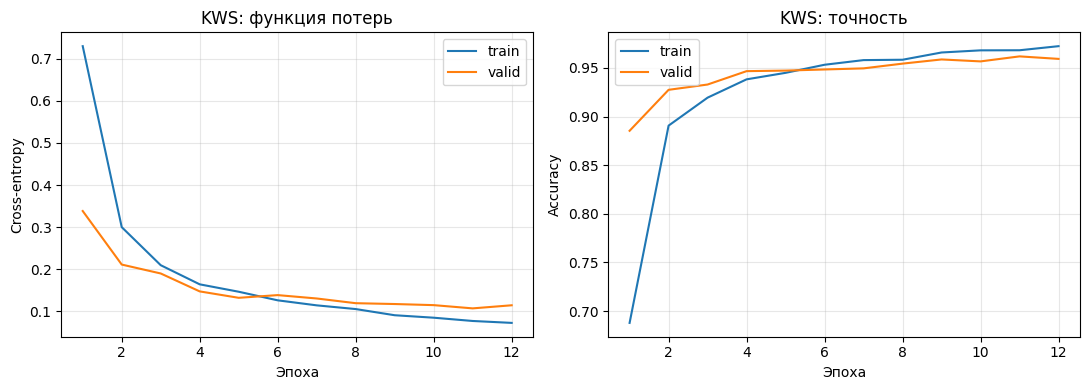

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(history['train_loss'])+1)
for split in ['train', 'valid']:
    axes[0].plot(epochs, history[f'{split}_loss'], label=split)
    axes[1].plot(epochs, history[f'{split}_acc'], label=split)
axes[0].set(title='KWS: функция потерь', xlabel='Эпоха', ylabel='Cross-entropy')
axes[1].set(title='KWS: точность', xlabel='Эпоха', ylabel='Accuracy')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Протестируйте модель (можно на своем голосе)**



Обратите внимание, что диктофон в смартфоне отдает формат (в основном) **.m4a** .

Проверяю лучшую модель на отдельной тестовой части и вывожу по одному реальному примеру каждого класса. Собственный голос не записывался. Для записи с телефона сначала нужно преобразовать .m4a в mono WAV; функция для WAV приведена ниже.

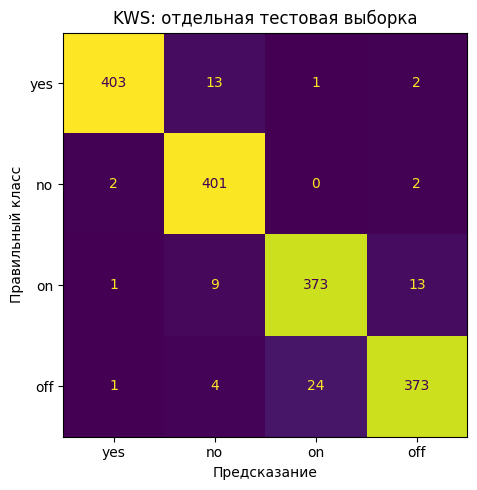

Test: loss=0.1137, accuracy=95.561%
yes → yes; p=[1. 0. 0. 0.]; 022cd682_nohash_0.wav
 no →  no; p=[0. 1. 0. 0.]; 03401e93_nohash_0.wav
 on →  on; p=[0. 0. 1. 0.]; 022cd682_nohash_0.wav
off → off; p=[0.    0.    0.018 0.982]; 03401e93_nohash_0.wav


In [12]:
@torch.inference_mode()
def predict_audio(path: Path):

    audio = load_audio(path, SAMPLE_RATE)
    audio = np.pad(audio[:SAMPLE_RATE], (0, max(0, SAMPLE_RATE-len(audio))))
    features = audio_to_features(torch.from_numpy(audio).unsqueeze(0)).to(DEVICE)
    probabilities = model(features).softmax(-1)[0].cpu().numpy()
    return CLASSES[int(probabilities.argmax())], probabilities


test_loss, test_acc = run_epoch(model, test_loader)
predicted = []
with torch.inference_mode():
    for features, _ in test_loader:
        predicted.extend(model(features.to(DEVICE)).argmax(1).cpu().tolist())
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix(test_data.tensors[1], predicted),
                       display_labels=CLASSES).plot(ax=ax, colorbar=False)
ax.set(title='KWS: отдельная тестовая выборка', xlabel='Предсказание', ylabel='Правильный класс')
plt.tight_layout()
plt.show()
print(f'Test: loss={test_loss:.4f}, accuracy={test_acc:.3%}')
for label, word in enumerate(CLASSES):
    path = next(path for path, target in test_files if target == label)
    prediction, probabilities = predict_audio(path)
    print(f'{word:>3} → {prediction:>3}; p={np.round(probabilities, 3)}; {path.name}')

**Кратко опишите полученный результат**

Точные метрики и выбранная эпоха выводятся ниже. Проверка характеризует четыре заданных класса на Speech Commands; класса «неизвестное слово» и тишины нет, поэтому это не универсальный детектор команд в непрерывном аудио.

In [13]:
best_epoch = int(np.argmin(history['valid_loss'])) + 1
print(f'Выбрана эпоха {best_epoch}: valid accuracy={history["valid_acc"][best_epoch-1]:.3%}.')
print(f'На отдельном test accuracy={test_acc:.3%}.')
print('Строки и столбцы on/off в матрице показывают, насколько модель различает близкие команды.')
print('Модель обучена только четырём словам: любой другой звук тоже получит один из четырёх классов.')

Выбрана эпоха 11: valid accuracy=96.188%.
На отдельном test accuracy=95.561%.
Строки и столбцы on/off в матрице показывают, насколько модель различает близкие команды.
Модель обучена только четырём словам: любой другой звук тоже получит один из четырёх классов.


**Результат.** Лучшая по valid loss — эпоха 11: accuracy на valid 96,19%, на отдельном test — 95,56% (1622 записи). Во всех четырёх показанных примерах класс определён правильно. В первых эпохах validation accuracy выше train accuracy: на train включён dropout, а на valid он выключен. Чаще всего модель путает on и off. Для этой небольшой CNN качество хорошее, но оно относится к четырём словам и условиям Speech Commands.

**Сконвертируйте модель в onnx формат**



Экспортирую обученную CNN в ONNX и проверяю выход через ONNX Runtime. Вход модели — готовый нормализованный log-mel `(B, 1, 40, 101)`; подготовка WAV остаётся в `audio_to_features`. Порядок классов `yes, no, on, off` записан в метаданные ONNX.

In [14]:
import onnx
import onnxruntime as ort

onnx_path = Path('kws.onnx')
model_cpu = copy.deepcopy(model).cpu().eval()
example = test_data.tensors[0][:4].contiguous()
torch.onnx.export(
    model_cpu, example, str(onnx_path), input_names=['log_mel'], output_names=['logits'],
    dynamic_axes={'log_mel': {0: 'batch'}, 'logits': {0: 'batch'}},
    opset_version=17, dynamo=False,
)
onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)

for key, value in {
    'classes': ','.join(CLASSES),
    'input': 'float32 [batch,1,40,101], normalized log-mel; audio_to_features in notebook',
    'audio': 'mono 16000 Hz; crop/pad to 16000 samples',
    'mel': 'n_fft=512,win_length=400,hop_length=160,n_mels=40,center=True,power=2,HTK',
    'normalization': 'log(mel+1e-6); per-example mean/std over all bins and frames; unbiased std; min 1e-5',
}.items():
    prop = onnx_model.metadata_props.add()
    prop.key, prop.value = key, value
onnx.save(onnx_model, str(onnx_path))
session = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
onnx_logits = session.run(None, {'log_mel': example.numpy()})[0]
with torch.inference_mode():
    torch_logits = model_cpu(example).numpy()
max_difference = float(np.abs(onnx_logits-torch_logits).max())
print('ONNX:', onnx_path.resolve(), 'байт:', onnx_path.stat().st_size)
print('Максимальная разница ONNX/PyTorch:', max_difference)
assert np.allclose(onnx_logits, torch_logits, atol=1e-4, rtol=1e-4)

ONNX: /Users/almazgajnetdinov/Developer/VK2/Аудио: STFT и Keyword Spotting/kws.onnx байт: 507043
Максимальная разница ONNX/PyTorch: 7.62939453125e-06


/var/folders/4_/309q59nx7hx1xgx4zk2jms400000gn/T/ipykernel_22167/1691038519.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter will be the default. To switch now, set dynamo=True in torch.onnx.export. This new exporter supports features like exporting LLMs with DynamicCache. We encourage you to try it and share feedback to help improve the experience. Learn more about the new export logic: https://pytorch.org/docs/stable/onnx_dynamo.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html.
  torch.onnx.export(
